### Matching TikTok songs with Billboard

Before comparing chart dates, lets first see whether the song titles and artists can be matched. TikTok has daily rankings and Billboard has weekly rankings, so we will compare the names separately first. 

##### Load the cleaned data

In [26]:
import pandas as pd
import unicodedata

billboard = pd.read_csv('../data/cleaned/billboard_cleaned.csv', low_memory=False)
tiktok_7day = pd.read_csv('../data/cleaned/tiktok_7day_cleaned.csv', low_memory=False)

print('Billboard rows:', len(billboard))
print('TikTok seven-day rows:', len(tiktok_7day))

Billboard rows: 355758
TikTok seven-day rows: 35602


##### Make text keys for comparison

In [27]:
# Standardize Unicode, ignore case, and remove spaces and punctuation.
def normalize_text(text):
    text = unicodedata.normalize('NFKC', str(text)).casefold()
    return ''.join(character for character in text if character.isalnum())

billboard['title_key'] = billboard['song'].map(normalize_text)
billboard['artist_key'] = billboard['artist'].map(normalize_text)
tiktok_7day['title_key'] = tiktok_7day['music_title'].map(normalize_text)
tiktok_7day['artist_key'] = tiktok_7day['music_author'].map(normalize_text)

##### Check TikTok song metadata variations


In [28]:
# Keep each distinct name combination once for each TikTok song ID.
tiktok_song_metadata = tiktok_7day[[
    'song_id', 'music_title', 'music_author', 'title_key', 'artist_key'
]].drop_duplicates()

# Count distinct normalized title/artist pairs for each ID.
variant_counts = (
    tiktok_song_metadata[['song_id', 'title_key', 'artist_key']]
    .drop_duplicates()
    .groupby('song_id')
    .size()
)

# These IDs have multiple pairs, so their metadata needs a closer look.
ids_with_variants = variant_counts[variant_counts > 1]

print('Unique TikTok song IDs:', tiktok_7day['song_id'].nunique())
print('IDs with more than one normalized title/artist pair:', len(ids_with_variants))
print('Variant pairs per ID:', ids_with_variants.value_counts().sort_index().to_dict())

variant_examples = tiktok_song_metadata[
    tiktok_song_metadata['song_id'].isin(ids_with_variants.index)
]
display(variant_examples[['song_id', 'music_title', 'music_author']].drop_duplicates().head(12))


Unique TikTok song IDs: 10509
IDs with more than one normalized title/artist pair: 44
Variant pairs per ID: {2: 41, 3: 3}


,song_id,music_title,music_author
195,7359310594140784656,Bad Wrist,MiyaAndRae
900,7372458803872483344,U My Everything (feat. Drake),Sexyy Red & Drake
1158,7359246255321171985,"Automotivo Amar, Ma Ma Ma",Dj Brunin XM & Mc Erikah & Bibi Babydoll
1169,7320812198715099137,SONIC.EXE - SUPER SLOWED,dawnicy
1446,6951779861246298113,Funny Song,Funny Song Studio & Sounds Reel
1614,7359246255321171985,"Automotivo Amar, Ma Ma Ma",Dj Brunin XM & Bibi Babydoll & Mc Erikah
1677,7371305782379939841,Yo Bunny (Pop like this Pt. 2 Remix),prodbycpkshawn & Ugly Andz.
1800,7374168077065898000,She Go - Summer Version Remix,iamB4
1844,7372552084678068240,sweet rally,ilysam
1884,7021345121224361986,Meet Me At Our Spot,THE ANXIETY & WILLOW & Tyler Cole


Some variations are only spelling or punctuation changes. Others are different title versions or artist orderings. The match summary below counts a TikTok song ID as matched if at least one of its normalized title/artist pairs appears in Billboard. This is a preliminary rule; the examples should be reviewed before relying on the final match rate.

In [29]:
# Create lookup tables of distinct Billboard title/artist pairs and titles.
billboard_pairs = billboard[['title_key', 'artist_key']].drop_duplicates()
billboard_pairs['exact_title_artist_match'] = True
billboard_titles = billboard[['title_key']].drop_duplicates()
billboard_titles['title_match'] = True

tiktok_song_pairs = tiktok_song_metadata[
    ['song_id', 'title_key', 'artist_key']
].drop_duplicates()

# Keep every TikTok pair; Billboard fields are added when a match is found.
pair_matches = tiktok_song_pairs.merge(
    billboard_pairs, on=['title_key', 'artist_key'], how='left'
).merge(billboard_titles, on='title_key', how='left')

# Missing match flags mean False; convert them to true/false values.
pair_matches['exact_title_artist_match'] = pair_matches['exact_title_artist_match'].fillna(False).astype(bool)
pair_matches['title_match'] = pair_matches['title_match'].fillna(False).astype(bool)

# Count an ID as matched if any of its name pairs matched.
song_matches = pair_matches.groupby('song_id').agg(
    exact_title_artist_match=('exact_title_artist_match', 'any'),
    title_match=('title_match', 'any')
)

# A title match includes exact artist matches; isolate title-only IDs separately.
title_only_match = song_matches['title_match'] & ~song_matches['exact_title_artist_match']

print('TikTok song IDs:', len(song_matches))
print('IDs with exact normalized title and artist match:', int(song_matches['exact_title_artist_match'].sum()))
print('Exact title and artist match rate:', round(song_matches['exact_title_artist_match'].mean() * 100, 2), '%')
print('IDs with any normalized title match:', int(song_matches['title_match'].sum()))
print('IDs with title match but no exact artist match:', int(title_only_match.sum()))
print('Title-only match rate:', round(title_only_match.mean() * 100, 2), '%')


TikTok song IDs: 10509
IDs with exact normalized title and artist match: 1230
Exact title and artist match rate: 11.7 %
IDs with any normalized title match: 2602
IDs with title match but no exact artist match: 1372
Title-only match rate: 13.06 %


##### Review a few examples

The counts give an overview, but a few examples help show why some matches are uncertain. These are examples to inspect, not a new matching rule.

Exact title and artist matches


In [30]:
# Show TikTok entries whose title and artist both match Billboard.
matched_examples = tiktok_song_metadata.merge(billboard_pairs, on=["title_key", "artist_key"], how="inner").drop_duplicates(["song_id", "music_title", "music_author"])
matched_examples[["music_title", "music_author"]].drop_duplicates().head(12)


,music_title,music_author
0,Espresso,Sabrina Carpenter
1,BOA,Megan Thee Stallion
2,Just A Girl,No Doubt
3,Believer,Imagine Dragons
4,Me Vs Me,Moneybagg Yo
5,Always Be My Baby,Mariah Carey
6,Never Lose Me,Flo Milli
7,golden hour,JVKE
8,Adore You,Miley Cyrus
9,This Is How We Do It,Montell Jordan


Same title, different artist text


In [31]:
# Keep IDs with a title match but no exact artist match.
title_only_ids = pair_matches.loc[pair_matches["title_match"] & ~pair_matches["exact_title_artist_match"], ["song_id", "title_key"]].drop_duplicates()

# Add the original names to inspect possible reasons for mismatch.
title_only_examples = title_only_ids.merge(
        tiktok_song_metadata[["song_id", "music_title", "music_author", "title_key"]].drop_duplicates(), 
        on=["song_id", "title_key"], how="left").merge(billboard[["title_key", "song", "artist"]].drop_duplicates(), 
                                                       on="title_key", how="left")
title_only_examples[["music_title", "music_author", "song", "artist"]].drop_duplicates().head(12)


,music_title,music_author,song,artist
0,Close,Cayo,Close,Nick Jonas Featuring Tove Lo
1,Close,Cayo,Close,Rae Sremmurd & Travis Scott
2,Close,Cayo,close,J. Cole
3,Ghost Town,Kanye West,Ghost Town,Cheap Trick
4,Ghost Town,Kanye West,Ghost Town,Adam Lambert
5,Ghost Town,Kanye West,Ghost Town,Kanye West Featuring PARTYNEXTDOOR
6,Ghost Town,Kanye West,Ghost Town,Benson Boone
7,In My Mind,Lyn Lapid,In My Mind,Heather Headley
8,Good Old Days,Macklemore & Kesha,Good Old Days,Macklemore Featuring Kesha
12,Proud of You,Kalieha,Proud Of You,Young Thug Featuring Lil Uzi Vert & Yung Kayo


No title match in Billboard history


In [32]:
# Find TikTok IDs whose normalized title did not appear in Billboard.
unmatched_ids = pair_matches.loc[~pair_matches["title_match"], ["song_id"]].drop_duplicates()

# Add readable TikTok names to review the unmatched titles.
unmatched_examples = unmatched_ids.merge(tiktok_song_metadata[["song_id", "music_title", "music_author"]].drop_duplicates(), on="song_id", how="left")
unmatched_examples[["music_title", "music_author"]].drop_duplicates().head(12)


,music_title,music_author
0,たぶん,YOASOBI
1,No Mastico Culebras,Los Chavalitos
2,WHAT I HAVE,Kelsea Ballerini
3,Hate Being Alone,Kodak Black
4,rock your hips,310babii & OhGeesy & BlueBucksClan
5,Where'd All the Time Go?,Dr. Dog
6,Spin Your Block,Clepto Maniack
7,Pink Matter,Frank Ocean
8,SONIC.EXE - ULTRA SLOWED,dawnicy
9,She Is Exactly Who God Created Her to Be,Quezzy The CEO


#### Group TikTok records by Billboard chart week

In [33]:
# Convert both date columns to real dates so pandas can work with weeks.
billboard["date"] = pd.to_datetime(billboard["date"])
tiktok_7day["date"] = pd.to_datetime(tiktok_7day["date"])

# Check the chart dates: in this dataset, Billboard dates fall on Wednesday.
print("Billboard chart weekdays:", billboard["date"].dt.day_name().value_counts().to_dict())

# Use Thursday-Wednesday calendar weeks to match the dataset chart-date weekday.
# This is a date-binning choice, not proof the chart uses the same tracking period.
tiktok_7day["billboard_week_date"] = (
    tiktok_7day["date"].dt.to_period("W-WED").dt.end_time.dt.normalize()
)

# Check how many daily TikTok dates are included in each weekly group.
daily_coverage = tiktok_7day.groupby("billboard_week_date")["date"].nunique()
print("TikTok weekly groups:", len(daily_coverage))
print("Daily dates per group (min/max):", daily_coverage.min(), daily_coverage.max())
display(daily_coverage.head(10))

# Some Billboard weeks may have no TikTok records, so list those weeks explicitly.
billboard_weeks_in_overlap = set(
    billboard.loc[
        billboard["date"].between(tiktok_7day["date"].min(), tiktok_7day["date"].max()),
        "date"
    ].drop_duplicates()
)
weeks_without_tiktok = sorted(billboard_weeks_in_overlap - set(daily_coverage.index))
print("Billboard weeks in the shared date range:", len(billboard_weeks_in_overlap))
print("Weeks without TikTok data:", weeks_without_tiktok)

Billboard chart weekdays: {'Wednesday': 355758}
TikTok weekly groups: 54
Daily dates per group (min/max): 3 7


billboard_week_date
2024-05-29    7
2024-06-05    7
2024-06-12    7
2024-06-19    7
2024-06-26    7
2024-07-03    7
2024-07-10    7
2024-07-17    7
2024-07-24    7
2024-07-31    7
Name: date, dtype: int64

Billboard weeks in the shared date range: 59
Weeks without TikTok data: [Timestamp('2025-04-30 00:00:00'), Timestamp('2025-05-14 00:00:00'), Timestamp('2025-05-21 00:00:00'), Timestamp('2025-05-28 00:00:00'), Timestamp('2025-06-04 00:00:00')]


In [34]:
# Summarize each TikTok song within each Wednesday-ending week.
# A lower rank number is better, so min() gives the best rank that week.
tiktok_weekly = (
    tiktok_7day.groupby(["billboard_week_date", "song_id"], as_index=False)
    .agg(
        best_tiktok_rank=("rank", "min"),
        days_in_tiktok_top100=("date", "nunique")
    )
)

print("Weekly song rows:", len(tiktok_weekly))
display(tiktok_weekly.head())

Weekly song rows: 17780


,billboard_week_date,song_id,best_tiktok_rank,days_in_tiktok_top100
0,2024-05-29,6694685951181981697,88,1
1,2024-05-29,6695136771358853121,27,2
2,2024-05-29,6696407789989791746,96,1
3,2024-05-29,6696408148661504002,75,1
4,2024-05-29,6696408607157651457,92,1


In [35]:
# Count available TikTok dates for each Billboard chart week, including zero-data weeks.
week_coverage = pd.Series(
    daily_coverage,
    index=daily_coverage.index
).reindex(sorted(billboard_weeks_in_overlap), fill_value=0)

# A full week has all seven daily rankings; keep incomplete weeks flagged.
complete_weeks = week_coverage[week_coverage == 7].index
incomplete_weeks = week_coverage[week_coverage < 7]
print("Complete weeks:", len(complete_weeks))
print("Incomplete or missing weeks:", len(incomplete_weeks))
display(incomplete_weeks.rename("TikTok dates available").to_frame())

# Keep the original summary and make a complete-week version for later comparisons.
tiktok_weekly_complete = tiktok_weekly[
    tiktok_weekly["billboard_week_date"].isin(complete_weeks)
].copy()
print("Song-week rows with complete TikTok coverage:", len(tiktok_weekly_complete))

Complete weeks: 43
Incomplete or missing weeks: 16


,TikTok dates available
billboard_week_date,
2024-11-27,4
2024-12-04,3
2025-02-05,6
2025-02-12,6
2025-03-26,6
2025-04-09,6
2025-04-23,6
2025-04-30,0
2025-05-07,4


Song-week rows with complete TikTok coverage: 14866


In [36]:
# Confirm a match only when both normalized title and artist match.
confirmed_crosswalk = (
    tiktok_song_metadata.merge(
        billboard[["title_key", "artist_key", "song", "artist"]].drop_duplicates(),
        on=["title_key", "artist_key"],
        how="inner"
    )
    [["song_id", "title_key", "artist_key", "song", "artist"]]
    .drop_duplicates()
)

# Check that one TikTok song ID does not point to multiple Billboard songs.
billboard_targets = confirmed_crosswalk[["song_id", "song", "artist"]].drop_duplicates()
targets_per_id = billboard_targets.groupby("song_id").size()
ambiguous_ids = targets_per_id[targets_per_id > 1]
print("Confirmed TikTok IDs:", billboard_targets["song_id"].nunique())
print("IDs linked to multiple Billboard songs:", len(ambiguous_ids))

# Keep only IDs with a single exact Billboard target for later comparison.
confirmed_crosswalk = confirmed_crosswalk[
    ~confirmed_crosswalk["song_id"].isin(ambiguous_ids.index)
].copy()

Confirmed TikTok IDs: 1230
IDs linked to multiple Billboard songs: 0


In [37]:
# Keep Billboard chart rows only for weeks with full TikTok coverage.
billboard_complete = billboard[billboard['date'].isin(complete_weeks)].copy()
billboard_complete = billboard_complete.rename(
    columns={'date': 'billboard_week_date', 'rank': 'billboard_rank'}
)

# If a Billboard song/artist has more than one row in a week, keep its best rank.
billboard_complete = (billboard_complete
    .groupby(['billboard_week_date', 'song', 'artist'], as_index=False)
    .agg(billboard_rank=('billboard_rank', 'min')))

# Add Billboard names to TikTok records with confirmed title-and-artist matches.
tiktok_confirmed = tiktok_7day.merge(
    confirmed_crosswalk[['song_id', 'song', 'artist']].drop_duplicates(),
    on='song_id',
    how='inner'
)

# Count each Billboard song/artist once per week, even if it has multiple TikTok IDs.
tiktok_confirmed_weekly = (tiktok_confirmed
    .groupby(['billboard_week_date', 'song', 'artist'], as_index=False)
    .agg(
        best_tiktok_rank=('rank', 'min'),
        days_in_tiktok_top100=('date', 'nunique')
    ))
tiktok_confirmed_weekly = tiktok_confirmed_weekly[
    tiktok_confirmed_weekly['billboard_week_date'].isin(complete_weeks)
].copy()

# Add the Billboard rank for the same song, artist, and chart week.
weekly_comparison = tiktok_confirmed_weekly.merge(
    billboard_complete[['billboard_week_date', 'song', 'artist', 'billboard_rank']],
    on=['billboard_week_date', 'song', 'artist'],
    how='left'
)

# A missing Billboard rank means the song was not on Billboard that week.
weekly_comparison['on_billboard_same_week'] = weekly_comparison['billboard_rank'].notna()
print('Confirmed Billboard song-weeks also found on TikTok:', len(weekly_comparison))
print('Also on Billboard that week:', int(weekly_comparison['on_billboard_same_week'].sum()))
print('Not on Billboard that week:', int((~weekly_comparison['on_billboard_same_week']).sum()))
display(weekly_comparison[[
    'billboard_week_date', 'song', 'artist', 'best_tiktok_rank',
    'days_in_tiktok_top100', 'billboard_rank', 'on_billboard_same_week'
]].head())

Confirmed Billboard song-weeks also found on TikTok: 1802
Also on Billboard that week: 137
Not on Billboard that week: 1665


,billboard_week_date,song,artist,best_tiktok_rank,days_in_tiktok_top100,billboard_rank,on_billboard_same_week
0,2024-05-29,"""10,000 Hours""",Dan + Shay & Justin Bieber,67,2,NaN,False
1,2024-05-29,"""Courtesy Of The Red, White And Blue (The Angr...",Toby Keith,85,1,NaN,False
2,2024-05-29,"""Paint It, Black""",The Rolling Stones,7,3,NaN,False
3,2024-05-29,"""Whenever, Wherever""",Shakira,75,1,NaN,False
4,2024-05-29,(There's) No Gettin' Over Me,Ronnie Milsap,35,2,NaN,False


### Compare ranks for the same week

Each row represents one Billboard song/artist credit in one chart week. TikTok IDs that match the same Billboard credit are combined. We compare ranks only for weeks with complete TikTok coverage. This is a descriptive comparison, not a test of whether TikTok caused a chart change.

In [38]:
# Keep only song-weeks that appeared on both TikTok and Billboard.
same_week = weekly_comparison[
    weekly_comparison['on_billboard_same_week']
].copy()

# Spearman correlation checks whether the two sets of ranks tend to move together.
# Ranks near 1 are better on both charts; a value near 0 means little rank pattern.
rank_correlation = same_week['best_tiktok_rank'].corr(
    same_week['billboard_rank'],
    method='spearman'
)

print('Song-weeks on both charts:', len(same_week))
print('Spearman rank correlation:', round(rank_correlation, 3))

# Look at a few rank pairs before interpreting the summary number.
display(same_week[[
    'billboard_week_date',
    'song',
    'artist',
    'best_tiktok_rank',
    'billboard_rank',
    'days_in_tiktok_top100'
]].head(10))


Song-weeks on both charts: 137
Spearman rank correlation: 0.032


,billboard_week_date,song,artist,best_tiktok_rank,billboard_rank,days_in_tiktok_top100
11,2024-05-29,Boa,Megan Thee Stallion,21,91.0,3
17,2024-05-29,Espresso,Sabrina Carpenter,12,6.0,1
36,2024-05-29,Like That,"""Future, Metro Boomin & Kendrick Lamar""",18,11.0,1
37,2024-05-29,Lose Control,Teddy Swims,49,7.0,3
39,2024-05-29,Made For Me,Muni Long,20,61.0,1
54,2024-05-29,Stargazing,Myles Smith,61,79.0,2
59,2024-05-29,Type Shit,"""Future, Metro Boomin, Travis Scott & Playboi ...",19,40.0,3
65,2024-06-05,"""Good Luck, Babe!""",Chappell Roan,19,31.0,4
70,2024-06-05,BAND4BAND,Central Cee & Lil Baby,1,22.0,2
99,2024-06-05,Pink Skies,Zach Bryan,72,6.0,2


The plot uses the same song-weeks as the correlation above. Each dot is one song-week; its position shows its TikTok rank and Billboard rank. Rank 1 is best on both charts.


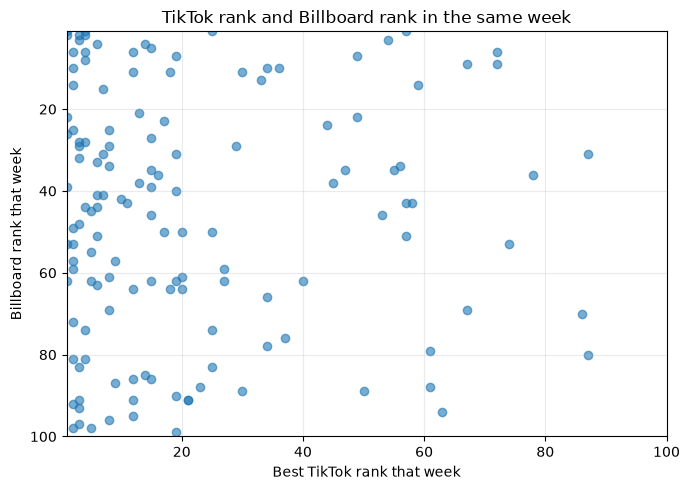

In [39]:
import matplotlib.pyplot as plt

# Draw one point for each song-week that appeared on both charts.
plt.figure(figsize=(7, 5))
plt.scatter(
    same_week['best_tiktok_rank'],
    same_week['billboard_rank'],
    alpha=0.6
)

# Label the axes so we can tell which chart each rank comes from.
plt.xlabel('Best TikTok rank that week')
plt.ylabel('Billboard rank that week')
plt.title('TikTok rank and Billboard rank in the same week')

# Rank 1 is best, so put it at the top of the Billboard axis.
plt.ylim(100, 1)
plt.xlim(1, 100)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#### Compare first observed dates

For matched songs seen on both charts during the shared date range, this compares their first TikTok date with their first Billboard date in that range. These are first observations in our data, not necessarily true debuts.


In [40]:
# Add the Billboard song and artist to each confirmed TikTok record.
tiktok_with_billboard_names = tiktok_7day.merge(
    confirmed_crosswalk[['song_id', 'song', 'artist']].drop_duplicates(),
    on='song_id',
    how='inner'
)

# Find the first TikTok date for each Billboard song/artist credit.
# This combines multiple TikTok IDs that refer to the same credit.
first_tiktok_date = tiktok_with_billboard_names.groupby(
    ['song', 'artist'], as_index=False
).agg(first_tiktok_date=('date', 'min'))

# Keep Billboard records only within the dates covered by the TikTok data.
shared_start = tiktok_7day['date'].min()
shared_end = tiktok_7day['date'].max()
billboard_in_shared_period = billboard[
    billboard['date'].between(shared_start, shared_end)
]

# Find each matched song/artist credit's first Billboard date in this period.
first_billboard_date = billboard_in_shared_period.groupby(
    ['song', 'artist'], as_index=False
).agg(first_billboard_date=('date', 'min'))

# Put the two first-observed dates together, with one row per Billboard credit.
timing_comparison = first_tiktok_date.merge(
    first_billboard_date,
    on=['song', 'artist'],
    how='inner'
)

# Positive days mean the first TikTok date in this dataset came before Billboard.
timing_comparison['days_tiktok_before_billboard'] = (
    timing_comparison['first_billboard_date']
    - timing_comparison['first_tiktok_date']
).dt.days

print('Matched Billboard song/artist credits seen on both charts:', len(timing_comparison))
print('TikTok observed first:', int((timing_comparison['days_tiktok_before_billboard'] > 0).sum()))
print('Same date:', int((timing_comparison['days_tiktok_before_billboard'] == 0).sum()))
print('Billboard observed first:', int((timing_comparison['days_tiktok_before_billboard'] < 0).sum()))

# Inspect a few records; these dates are first observed in this dataset window only.
display(timing_comparison[[
    'song', 'artist', 'first_tiktok_date', 'first_billboard_date',
    'days_tiktok_before_billboard'
]].head(10))


Matched Billboard song/artist credits seen on both charts: 206
TikTok observed first: 124
Same date: 5
Billboard observed first: 77


,song,artist,first_tiktok_date,first_billboard_date,days_tiktok_before_billboard
0,"""Dum, Dumb, And Dumber""","""Lil Baby, Young Thug & Future""",2025-05-04,2025-01-15,-109
1,"""Good Luck, Babe!""",Chappell Roan,2024-05-30,2024-05-29,-1
2,"""So Long, London""",Taylor Swift,2024-06-21,2024-05-29,-23
3,A Bar Song (Tipsy),Shaboozey,2024-07-21,2024-05-29,-53
4,A Holly Jolly Christmas,Burl Ives,2024-12-03,2024-11-27,-6
5,Abracadabra,Lady Gaga,2025-03-07,2025-02-12,-23
6,Actin Up,Tommy Richman,2025-02-28,2025-04-30,61
7,Again,Fetty Wap,2024-12-19,2025-02-12,55
8,Alibi,"""Sevdaliza, Pabllo Vittar & Yseult""",2024-07-11,2024-07-31,20
9,All I Want For Christmas Is You,Mariah Carey,2024-10-31,2024-11-27,27


#### Summarize TikTok-first gaps

This cell looks only at Billboard song/artist credits whose first TikTok date in the dataset came before their first Billboard date in the shared period. The median is the middle gap; the 25th and 75th percentiles describe the middle half of the gaps.

In [41]:
# Keep cases where the TikTok date came before the Billboard date.
tiktok_first_cases = timing_comparison.loc[
    timing_comparison['days_tiktok_before_billboard'] > 0,
    'days_tiktok_before_billboard'
]

# The median is the middle gap; the 25th and 75th percentiles show the middle half.
print('Cases where TikTok was observed first:', len(tiktok_first_cases))
print('Median days before Billboard:', tiktok_first_cases.median())
print('Middle-half range (days):',
      tiktok_first_cases.quantile(0.25), 'to',
      tiktok_first_cases.quantile(0.75))


Cases where TikTok was observed first: 124
Median days before Billboard: 15.0
Middle-half range (days): 4.0 to 41.5


#### Summarize the timing gap

These cells count and plot which chart was observed first for each matched Billboard song/artist credit. A positive day gap means TikTok was observed first; a negative gap means Billboard was. The dates are limited to the datasets’ shared period.

In [42]:
# The timing table already has one row per Billboard song/artist credit.
timing_by_song = timing_comparison.copy()
day_gap = timing_by_song['days_tiktok_before_billboard']

# Count whether TikTok or Billboard was observed first, or on the same date.
timing_counts = pd.Series({
    'TikTok observed first': int((day_gap > 0).sum()),
    'Same date': int((day_gap == 0).sum()),
    'Billboard observed first': int((day_gap < 0).sum()),
})

# Convert each count into a share of the matched songs in this table.
timing_summary = pd.DataFrame({'song_count': timing_counts})
timing_summary['percent'] = timing_summary['song_count'] / len(timing_by_song) * 100

display(timing_summary.round(1))

,song_count,percent
TikTok observed first,124,60.2
Same date,5,2.4
Billboard observed first,77,37.4


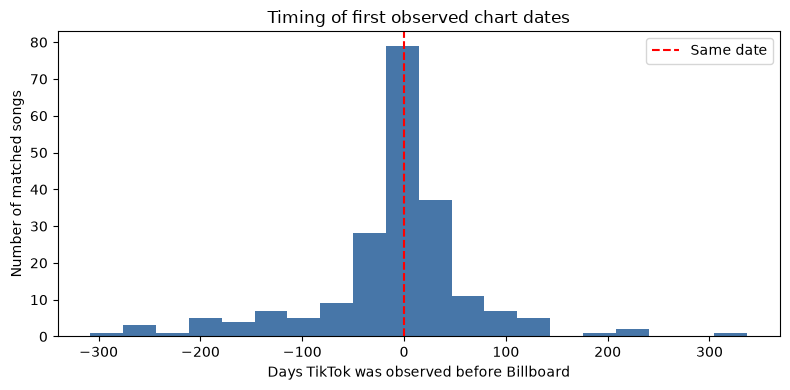

In [43]:
import matplotlib.pyplot as plt

# Draw a bar for how many matched songs have each observed date gap.
plt.figure(figsize=(8, 4))
plt.hist(timing_by_song['days_tiktok_before_billboard'], bins=20, color='#4776A8')

# Zero means both were first observed on the same date.
plt.axvline(0, color='red', linestyle='--', label='Same date')
plt.xlabel('Days TikTok was observed before Billboard')
plt.ylabel('Number of matched songs')
plt.title('Timing of first observed chart dates')
plt.legend()
plt.tight_layout()
plt.show()

# Positive gaps mean TikTok was observed first; negative gaps mean Billboard was.

#### Compare week-to-week Billboard movement

This section checks whether matched songs that also appeared on TikTok moved up or down on Billboard from one chart week to the next. We compare consecutive Billboard weeks only. A positive rank change means the song moved closer to number 1. This describes patterns in the data; it does not show that TikTok caused the movement.

In [44]:
# Attach each TikTok song ID to its confirmed Billboard title and artist.
tiktok_with_billboard_names = tiktok_7day.merge(
    confirmed_crosswalk[["song_id", "song", "artist"]],
    on="song_id",
    how="inner"
)

# Combine multiple TikTok IDs for the same Billboard song and week.
# The lowest number is the best TikTok rank that week.
tiktok_billboard_weekly = (
    tiktok_with_billboard_names
    .groupby(["billboard_week_date", "song", "artist"], as_index=False)
    .agg(best_tiktok_rank=("rank", "min"))
)

# Add each song's previous Billboard rank and chart date.
billboard_movement = billboard_complete.merge(
    confirmed_crosswalk[["song", "artist"]].drop_duplicates(),
    on=["song", "artist"],
    how="inner"
).sort_values(["song", "artist", "billboard_week_date"])

billboard_movement["previous_billboard_rank"] = (
    billboard_movement.groupby(["song", "artist"])["billboard_rank"].shift(1)
)
billboard_movement["previous_chart_date"] = (
    billboard_movement.groupby(["song", "artist"])["billboard_week_date"].shift(1)
)

# Keep only cases where the chart dates are exactly one week apart.
billboard_movement["days_between_charts"] = (
    billboard_movement["billboard_week_date"] - billboard_movement["previous_chart_date"]
).dt.days
consecutive_weeks = billboard_movement[
    billboard_movement["days_between_charts"] == 7
].copy()

# Positive means the song moved toward number 1; negative means it fell.
consecutive_weeks["billboard_rank_change"] = (
    consecutive_weeks["previous_billboard_rank"] - consecutive_weeks["billboard_rank"]
)

# Keep weeks when the matched song also appeared on TikTok.
billboard_tiktok_movement = consecutive_weeks.merge(
    tiktok_billboard_weekly,
    on=["billboard_week_date", "song", "artist"],
    how="inner"
)

print("Matched song-weeks with consecutive Billboard charts and TikTok data:", len(billboard_tiktok_movement))
display(billboard_tiktok_movement[[
    "billboard_week_date", "song", "artist",
    "previous_billboard_rank", "billboard_rank",
    "billboard_rank_change", "best_tiktok_rank"
]].head())

Matched song-weeks with consecutive Billboard charts and TikTok data: 66


,billboard_week_date,song,artist,previous_billboard_rank,billboard_rank,billboard_rank_change,best_tiktok_rank
0,2024-06-05,"""Good Luck, Babe!""",Chappell Roan,43.0,31,12.0,19
1,2024-07-24,A Bar Song (Tipsy),Shaboozey,2.0,1,1.0,57
2,2024-12-25,A Holly Jolly Christmas,Burl Ives,5.0,5,0.0,15
3,2025-03-12,Abracadabra,Lady Gaga,31.0,29,2.0,3
4,2024-08-07,Alibi,"""Sevdaliza, Pabllo Vittar & Yseult""",95.0,98,-3.0,2


In [45]:
# Label each song-week based on its Billboard rank change.
billboard_tiktok_movement["movement"] = "Stayed the same"
billboard_tiktok_movement.loc[
    billboard_tiktok_movement["billboard_rank_change"] > 0, "movement"
] = "Improved"
billboard_tiktok_movement.loc[
    billboard_tiktok_movement["billboard_rank_change"] < 0, "movement"
] = "Worsened"

# Count song-weeks in each group and calculate the median ranks and changes.
movement_summary = (
    billboard_tiktok_movement.groupby("movement")
    .agg(
        song_weeks=("song", "size"),
        median_tiktok_rank=("best_tiktok_rank", "median"),
        median_billboard_rank_change=("billboard_rank_change", "median")
    )
)
movement_summary["percent_of_song_weeks"] = (
    movement_summary["song_weeks"] / len(billboard_tiktok_movement) * 100
)

# Put the categories in an easy-to-read order.
movement_summary = movement_summary.reindex(["Improved", "Stayed the same", "Worsened"])
display(movement_summary.round(1))

,song_weeks,median_tiktok_rank,median_billboard_rank_change,percent_of_song_weeks
movement,,,,
Improved,31,15.0,8.0,47.0
Stayed the same,6,4.5,0.0,9.1
Worsened,29,14.0,-7.0,43.9


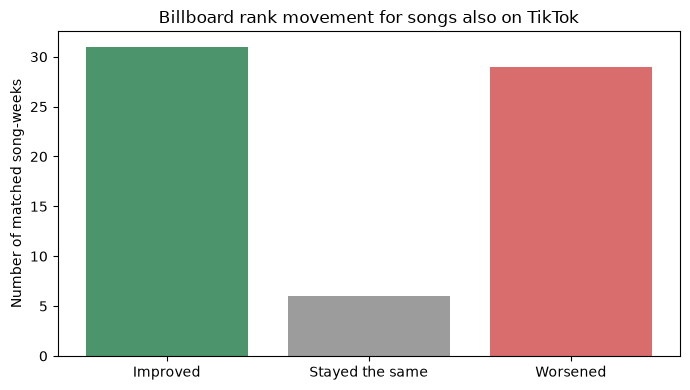

In [46]:
# Keep the bars in the same order as the summary table.
movement_order = ["Improved", "Stayed the same", "Worsened"]
plot_data = movement_summary.reindex(movement_order)

# Draw one bar for the number of song-weeks in each movement group.
plt.figure(figsize=(7, 4))
plt.bar(plot_data.index, plot_data["song_weeks"], color=["#4C956C", "#9C9C9C", "#D96C6C"])
plt.ylabel("Number of matched song-weeks")
plt.title("Billboard rank movement for songs also on TikTok")
plt.tight_layout()
plt.show()

#### Compare TikTok appearances with next-week Billboard movement

For each confirmed matched song/artist credit, compare its Billboard rank this week with its rank one week later. Then check whether the song appeared in the TikTok top 100 during the starting week. The TikTok-absent group means no confirmed TikTok match appeared in the available seven-day records that week. Both groups use only consecutive Billboard weeks with complete TikTok coverage in the starting week.

In [47]:
# Keep Billboard credits with confirmed TikTok matches, for complete TikTok weeks.
matched_billboard_weeks = billboard_complete.merge(
    confirmed_crosswalk[["song", "artist"]].drop_duplicates(),
    on=["song", "artist"],
    how="inner"
).sort_values(["song", "artist", "billboard_week_date"])

# Get the next chart date and rank for each song/artist credit.
matched_billboard_weeks["next_chart_date"] = (
    matched_billboard_weeks.groupby(["song", "artist"])["billboard_week_date"].shift(-1)
)
matched_billboard_weeks["next_billboard_rank"] = (
    matched_billboard_weeks.groupby(["song", "artist"])["billboard_rank"].shift(-1)
)

# Keep only weeks where the next Billboard chart is exactly seven days later.
next_week_comparison = matched_billboard_weeks[
    (matched_billboard_weeks["next_chart_date"] - matched_billboard_weeks["billboard_week_date"]).dt.days == 7
].copy()

# Positive change means the song moved closer to number 1 next week.
next_week_comparison["billboard_rank_change"] = (
    next_week_comparison["billboard_rank"] - next_week_comparison["next_billboard_rank"]
)

# Add the best TikTok rank in the starting week, when there was one.
next_week_comparison = next_week_comparison.merge(
    tiktok_confirmed_weekly[["billboard_week_date", "song", "artist", "best_tiktok_rank"]],
    on=["billboard_week_date", "song", "artist"],
    how="left"
)
next_week_comparison["tiktok_this_week"] = next_week_comparison["best_tiktok_rank"].notna()

# Label each next-week change as improved, the same, or worsened.
next_week_comparison["movement"] = "Stayed the same"
next_week_comparison.loc[next_week_comparison["billboard_rank_change"] > 0, "movement"] = "Improved"
next_week_comparison.loc[next_week_comparison["billboard_rank_change"] < 0, "movement"] = "Worsened"

# Compare the number and share of outcomes for weeks with and without TikTok presence.
next_week_counts = pd.crosstab(
    next_week_comparison["tiktok_this_week"],
    next_week_comparison["movement"]
).reindex(columns=["Improved", "Stayed the same", "Worsened"], fill_value=0)
next_week_summary = next_week_counts.div(next_week_counts.sum(axis=1), axis=0) * 100
next_week_summary.insert(0, "song_weeks", next_week_counts.sum(axis=1))
next_week_summary.index = ["No TikTok match that week", "TikTok match that week"]

print("Consecutive matched Billboard song-weeks compared:", len(next_week_comparison))
display(next_week_summary.round(1))
print("Median Billboard rank change (positive means improved):")
display(next_week_comparison.groupby("tiktok_this_week")["billboard_rank_change"].median().rename(index={False: "No TikTok match that week", True: "TikTok match that week"}).to_frame(name="median_rank_change"))

Consecutive matched Billboard song-weeks compared: 1289


movement,song_weeks,Improved,Stayed the same,Worsened
No TikTok match that week,1174,36.9,14.2,48.9
TikTok match that week,115,49.6,8.7,41.7


Median Billboard rank change (positive means improved):


,median_rank_change
tiktok_this_week,
No TikTok match that week,0.0
TikTok match that week,0.0


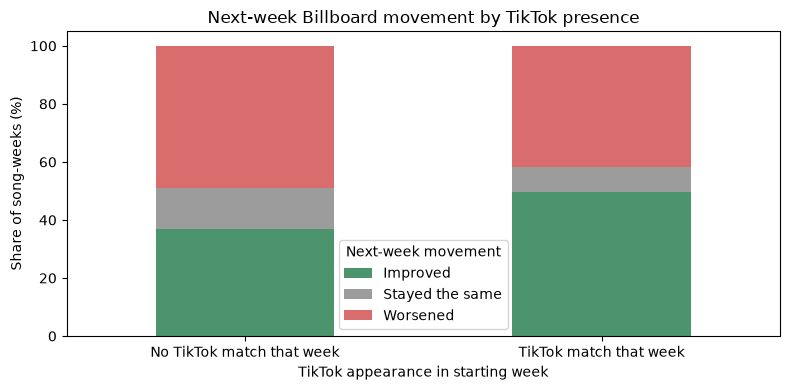

In [48]:
# Plot the share of song-weeks in each movement group.
movement_order = ["Improved", "Stayed the same", "Worsened"]
plot_data = next_week_summary[movement_order]

plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4),
    color=["#4C956C", "#9C9C9C", "#D96C6C"]
)
plt.ylabel("Share of song-weeks (%)")
plt.xlabel("TikTok appearance in starting week")
plt.title("Next-week Billboard movement by TikTok presence")
plt.xticks(rotation=0)
plt.legend(title="Next-week movement")
plt.tight_layout()
plt.show()

In this comparison, matched songs with a TikTok top-100 appearance in the starting week improved more often by the next Billboard week than matched songs without one (49.6% versus 36.9%). They also worsened less often (41.7% versus 48.9%). The groups are very different in size: 115 versus 1,174 song-weeks. The median rank change is zero in both groups, so these percentages describe how often ranks moved in either direction, not a typical size of movement. This is an association in the observed data, not proof that TikTok caused the Billboard changes. It covers matched songs already on Billboard in consecutive weeks; it does not measure songs entering Billboard from outside the chart.

#### Check next-week Billboard appearances

This check starts with confirmed TikTok song/artist credits that are not on Billboard in the same chart week. It asks whether each one appears on Billboard the following week. The weekly absence does not tell us whether the song is a first-time debut or a return, so this analysis calls them next-week appearances.

In [49]:
# Make one row for each Billboard song/artist credit in each chart week.
billboard_all_weeks = billboard.groupby(
    ["date", "song", "artist"], as_index=False
).agg(billboard_rank=("rank", "min")).rename(
    columns={"date": "billboard_week_date"}
)

# Start with confirmed TikTok song-weeks from weeks with full TikTok coverage.
tiktok_appearance_check = tiktok_confirmed_weekly.copy()
tiktok_appearance_check["next_chart_date"] = (
    tiktok_appearance_check["billboard_week_date"] + pd.Timedelta(days=7)
)

# Keep only rows where the following Billboard chart is available in the data.
available_billboard_dates = set(billboard_all_weeks["billboard_week_date"])
tiktok_appearance_check = tiktok_appearance_check[
    tiktok_appearance_check["next_chart_date"].isin(available_billboard_dates)
].copy()

# Check whether each matched song was on Billboard in the starting week.
current_billboard = billboard_all_weeks.rename(
    columns={"billboard_rank": "current_billboard_rank"}
)
tiktok_appearance_check = tiktok_appearance_check.merge(
    current_billboard,
    on=["billboard_week_date", "song", "artist"],
    how="left"
)

# Check whether it appeared on Billboard seven days later.
next_billboard = billboard_all_weeks.rename(
    columns={"billboard_week_date": "next_chart_date",
             "billboard_rank": "next_billboard_rank"}
)
tiktok_appearance_check = tiktok_appearance_check.merge(
    next_billboard,
    on=["next_chart_date", "song", "artist"],
    how="left"
)

# Keep TikTok song-weeks absent from Billboard in the starting week.
tiktok_absent_from_billboard = tiktok_appearance_check[
    tiktok_appearance_check["current_billboard_rank"].isna()
].copy()
tiktok_absent_from_billboard["on_billboard_next_week"] = (
    tiktok_absent_from_billboard["next_billboard_rank"].notna()
)

# Count next-week appearances and calculate the share of this group.
absent_count = len(tiktok_absent_from_billboard)
next_week_appearances = int(tiktok_absent_from_billboard["on_billboard_next_week"].sum())
print("Matched TikTok song-weeks absent from Billboard, with a next chart available:", absent_count)
print("Appeared on Billboard the following week:", next_week_appearances)
if absent_count > 0:
    print("Share appearing the following week:", round(next_week_appearances / absent_count * 100, 1), "%")

# Review a few cases with the strongest TikTok rank in the starting week.
examples = tiktok_absent_from_billboard[
    tiktok_absent_from_billboard["on_billboard_next_week"]
].sort_values("best_tiktok_rank").head(10)
display(examples[[
    "billboard_week_date", "song", "artist",
    "best_tiktok_rank", "days_in_tiktok_top100", "next_billboard_rank"
]])

Matched TikTok song-weeks absent from Billboard, with a next chart available: 1665
Appeared on Billboard the following week: 31
Share appearing the following week: 1.9 %


,billboard_week_date,song,artist,best_tiktok_rank,days_in_tiktok_top100,next_billboard_rank
801,2024-10-02,Keep Up,Odetari,1,2,96.0
1499,2025-02-26,Me Jalo,Fuerza Regida & Grupo Frontera,1,5,81.0
360,2024-07-24,Apple,Charli xcx,1,4,81.0
1540,2025-03-05,Ms. Whitman,Bhad Bhabie,2,1,56.0
1757,2025-07-09,"""Courtesy Of The Red, White And Blue (The Angr...",Toby Keith,2,4,31.0
359,2024-07-24,Alibi,"""Sevdaliza, Pabllo Vittar & Yseult""",2,1,95.0
429,2024-07-31,Linger (SiriusXM Session),Royel Otis,3,2,94.0
940,2024-10-23,Love Somebody,Morgan Wallen,5,1,1.0
961,2024-10-23,Tu Boda,Oscar Maydon & Fuerza Regida,6,4,23.0
557,2024-08-21,Sailor Song,Gigi Perez,7,7,98.0


#### Does TikTok rank align with next-week Billboard movement?

This comparison uses matched songs that were on Billboard in two consecutive chart weeks and had a TikTok seven-day Top 100 rank in the starting week. TikTok ranks are grouped into bands; lower numbers indicate a better rank. Billboard rank change is the current rank minus next week's rank, so positive values indicate improvement. Each row is a song-week, and a song may appear more than once. This is descriptive and does not establish causation.

Matched song-weeks with TikTok ranks: 115
Distinct songs: 74
Spearman correlation between TikTok rank and next-week Billboard rank change: -0.131


,song_weeks,unique_songs,median_billboard_rank_change,improved,stayed_same,worsened,improved_pct,stayed_same_pct,worsened_pct
tiktok_rank_tier,,,,,,,,,
1–10,51,36,1.0,27,4,20,52.9,7.8,39.2
11–25,31,24,2.0,17,3,11,54.8,9.7,35.5
26–50,15,14,0.0,7,1,7,46.7,6.7,46.7
51–100,18,16,-1.5,6,2,10,33.3,11.1,55.6


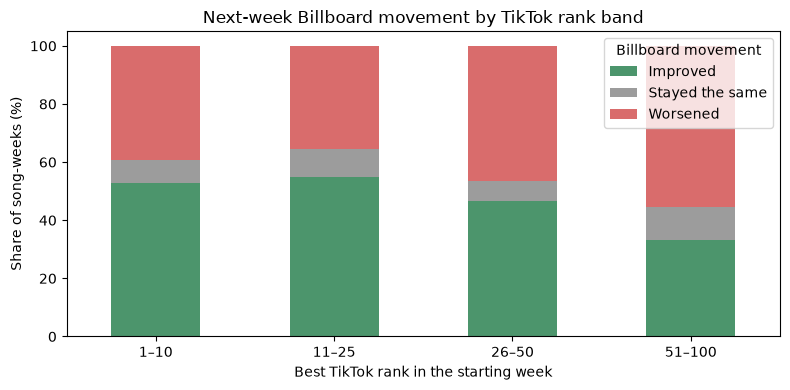

In [50]:
# Keep song-weeks with a confirmed TikTok match in the starting week.
tiktok_ranked_movement = next_week_comparison.loc[
    next_week_comparison["tiktok_this_week"]
].copy()

# Group lower (better) TikTok ranks into readable bands.
rank_bins = [0, 10, 25, 50, 100]
rank_labels = ["1–10", "11–25", "26–50", "51–100"]
tiktok_ranked_movement["tiktok_rank_tier"] = pd.cut(
    tiktok_ranked_movement["best_tiktok_rank"],
    bins=rank_bins,
    labels=rank_labels,
    include_lowest=True
)

# Summarize next-week Billboard movement within each TikTok rank band.
rank_tier_summary = (
    tiktok_ranked_movement.groupby("tiktok_rank_tier", observed=False)
    .agg(
        song_weeks=("song", "size"),
        unique_songs=("song", "nunique"),
        median_billboard_rank_change=("billboard_rank_change", "median"),
        improved=("billboard_rank_change", lambda values: values.gt(0).sum()),
        stayed_same=("billboard_rank_change", lambda values: values.eq(0).sum()),
        worsened=("billboard_rank_change", lambda values: values.lt(0).sum())
    )
)

for movement in ["improved", "stayed_same", "worsened"]:
    rank_tier_summary[f"{movement}_pct"] = (
        rank_tier_summary[movement] / rank_tier_summary["song_weeks"] * 100
    )

print("Matched song-weeks with TikTok ranks:", len(tiktok_ranked_movement))
print("Distinct songs:", tiktok_ranked_movement["song"].nunique())
print(
    "Spearman correlation between TikTok rank and next-week Billboard rank change:",
    round(
        tiktok_ranked_movement["best_tiktok_rank"].corr(
            tiktok_ranked_movement["billboard_rank_change"], method="spearman"
        ),
        3
    )
)
display(rank_tier_summary.round(1))

# Compare the share of song-weeks improving, unchanged, or worsening.
movement_columns = ["improved_pct", "stayed_same_pct", "worsened_pct"]
rank_tier_summary[movement_columns].rename(columns={
    "improved_pct": "Improved",
    "stayed_same_pct": "Stayed the same",
    "worsened_pct": "Worsened"
}).plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4),
    color=["#4C956C", "#9C9C9C", "#D96C6C"]
)
plt.ylabel("Share of song-weeks (%)")
plt.xlabel("Best TikTok rank in the starting week")
plt.title("Next-week Billboard movement by TikTok rank band")
plt.xticks(rotation=0)
plt.legend(title="Billboard movement")
plt.tight_layout()
plt.show()